In [ ]:
# John Gallagher
# October 5, 2026

# Generate a heatmap of compute time for 10k samples:
# Parameters tau, tol, iter, iter


# import argparse
# parser = argparse.ArgumentParser()
# parser.add_argument('T', type=float, choices=[1, 2, 3, 4, 5],
#                     help='final integration time')
# args = parser.parse_args()

import sys
from pathlib import Path
CHMC = Path.cwd().parents[1]   # compute_heatmaps -> scripts -> CHMC
sys.path.insert(0, str(CHMC))



SCRATCH = Path("CHMC/scripts/compute_heatmaps")

base = SCRATCH/Path(f"neals_results")
base.mkdir(parents=True, exist_ok=True)


import time
import json

# JAX
import jax
jax.config.update("jax_enable_x64", True)


from jax import jit, grad, vmap
import jax.random as jr
import jax.numpy as jnp
import jax.scipy as jsp

# Custom
from datatypes import QP, IntegratorConfig,  gen_configs
from target import neals_funnel_logpdf
from hamiltonian import logpdf_hamiltonian
from sampler import gen_chmc_kernel, gen_hmc_kernel, hmc_sampler, chmc_sampler
from databasing import write_tree


t

τ=0.5, N=6, tol=0.001
τ=0.25, N=12, tol=0.001
τ=0.125, N=24, tol=0.001
τ=0.0625, N=48, tol=0.001
τ=0.03125, N=96, tol=0.001
τ=0.5, N=6, tol=0.01
τ=0.25, N=12, tol=0.01
τ=0.125, N=24, tol=0.01
τ=0.0625, N=48, tol=0.01
τ=0.03125, N=96, tol=0.01
τ=0.5, N=6, tol=0.1
τ=0.25, N=12, tol=0.1
τ=0.125, N=24, tol=0.1
τ=0.0625, N=48, tol=0.1
τ=0.03125, N=96, tol=0.1
τ=0.5, N=6, tol=0.3
τ=0.25, N=12, tol=0.3
τ=0.125, N=24, tol=0.3
τ=0.0625, N=48, tol=0.3
τ=0.03125, N=96, tol=0.3


In [50]:
for tol_idx, tol in enumerate(tols):
    for l in range(len(lens)):
        for tau_idx in range(len(taus)):
            print(configs[tol_idx][tau_idx])

IntegratorConfig(τ=0.5, T=3.0, N=6, tol=Array(0.001, dtype=float64), max_iter=10, constant_p=False, integrator='AA', AA_m=5, AA_beta=1, n_pts=4, trajectory=False, gen_gauss=False, debug=False)
IntegratorConfig(τ=0.25, T=3.0, N=12, tol=Array(0.001, dtype=float64), max_iter=10, constant_p=False, integrator='AA', AA_m=5, AA_beta=1, n_pts=4, trajectory=False, gen_gauss=False, debug=False)
IntegratorConfig(τ=0.125, T=3.0, N=24, tol=Array(0.001, dtype=float64), max_iter=10, constant_p=False, integrator='AA', AA_m=5, AA_beta=1, n_pts=4, trajectory=False, gen_gauss=False, debug=False)
IntegratorConfig(τ=0.0625, T=3.0, N=48, tol=Array(0.001, dtype=float64), max_iter=10, constant_p=False, integrator='AA', AA_m=5, AA_beta=1, n_pts=4, trajectory=False, gen_gauss=False, debug=False)
IntegratorConfig(τ=0.03125, T=3.0, N=96, tol=Array(0.001, dtype=float64), max_iter=10, constant_p=False, integrator='AA', AA_m=5, AA_beta=1, n_pts=4, trajectory=False, gen_gauss=False, debug=False)
IntegratorConfig(τ=0.

In [ ]:
for tol_idx, tol in enumerate(tols):
    for ll in range(len(lens)):
        for tau_idx in range(len(taus)):
            chmc = gen_chmc_kernel(H, configs[tol_idx][tau_idx])
            scan_chmc = jax.jit(lambda init, xs: jax.lax.scan(chmc, init, xs))
            for nth_run in range(n_runs):
                key = jr.PRNGKey(nth_run)
                keya, keyb = jr.split(key)
                chain_keys = jr.split(keya, lens[ll])

                qp0 = QP(jr.normal(keyb, shape=(2*d,)))
                init = [qp0, 1, False]

                # Finish input preparation before compiling or timing.
                jax.block_until_ready((init, chain_keys))

                # Compile once per (length, tau, T). No execution warm-up.
                if nth_run == 0:
                    print(f"Compiling T={T}, tau={taus[tau_idx]}, length={lens[ll]}", flush=True)
                    compiled_scan = scan_chmc.lower(init, chain_keys).compile()

                # Time this chain only; wait for the entire result.
                # print(f"Starting T={T}, tau={taus[tau_idx]}, length={lens[ll]}, run={nth_run}", flush=True)
                start = time.perf_counter()
                result = compiled_scan(init, chain_keys)
                jax.block_until_ready(result)
                elapsed = time.perf_counter() - start
                _, (qps, deltaHs, accepted) = result

                folder = (
                    base
                    / methods[0]
                    / f"tau_{taus[tau_idx]}"
                    / f"T_{T}"
                    / f"tol_{tols[tol_idx]}"
                    / f"len_{lens[ll]}"
                )
                folder.mkdir(parents=True, exist_ok=True)
                path = folder / f"run_{nth_run}.npz"
                jnp.savez(
                    path,
                    q=jnp.asarray(qps.q),
                    deltaHs=jnp.asarray(deltaHs),
                    accepted=jnp.asarray(accepted),
                    runtime = jnp.float64(elapsed),
                )
                # print(f"Saved {path}: runtime={elapsed:.6f}s", flush=True)
                # records.append({
                #     "method": methods[0],
                #     "tau": float(taus[tau_idx]),
                #     "T": float(T),
                #     "length": int(lens[ll]),
                #     "run": int(nth_run),
                #     "path": str(path.relative_to(base)),
                # })

with open(method_base / f"metadata_{methods[0]}_T_{T}.json", "w") as f:
    json.dump({"files": records}, f, indent=2)

write_tree(method_base, method_base / f'file_tree_{methods[0]}_T_{T}.txt')


Compiling T=3.0, tau=0.5, length=10000
Compiling T=3.0, tau=0.25, length=10000
Compiling T=3.0, tau=0.125, length=10000
Compiling T=3.0, tau=0.0625, length=10000


KeyboardInterrupt: 

In [11]:
base

PosixPath('CHMC/scripts/compute_heatmaps/neals_results')

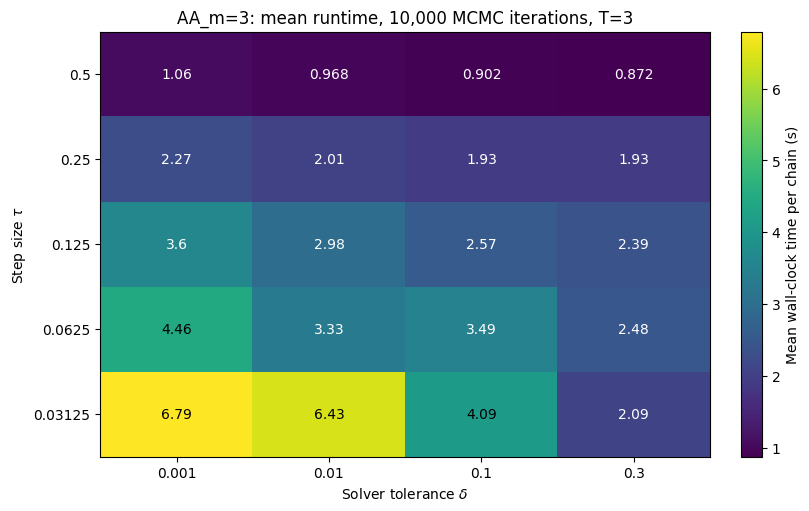

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

def plot_compute_heatmap(base, method, T=3.0, length=1_000):
    """Return fig, ax, mean_seconds, run_counts, taus, tols.

    Arrays have tau as the row axis and tolerance as the column axis, both in
    ascending order. Axes display discrete sweep values at equally spaced cells.
    Missing combinations are NaN (gray); means use all available saved runs.
    """
    root = Path(base) / method
    groups = defaultdict(list)

    for path in sorted(root.glob("tau_*/T_*/tol_*/len_*/run_*.npz")):
        tau_dir, time_dir, tol_dir, length_dir, _ = path.relative_to(root).parts
        saved_T = float(time_dir.removeprefix("T_"))
        saved_length = int(length_dir.removeprefix("len_"))
        if not np.isclose(saved_T, T, rtol=1e-12, atol=0) or saved_length != length:
            continue

        tau = float(tau_dir.removeprefix("tau_"))
        tol = float(tol_dir.removeprefix("tol_"))
        with np.load(path, allow_pickle=False) as data:
            runtime = float(data["runtime"].item())
        if not np.isfinite(runtime) or runtime < 0:
            raise ValueError(f"Invalid runtime in {path}: {runtime}")
        groups[tau, tol].append(runtime)

    if not groups:
        raise FileNotFoundError(
            f"No run files found under {root} for T={T}, length={length}."
        )

    taus = np.array(sorted({tau for tau, _ in groups}))
    tols = np.array(sorted({tol for _, tol in groups}))
    mean_seconds = np.full((len(taus), len(tols)), np.nan)
    run_counts = np.zeros(mean_seconds.shape, dtype=int)

    for i, tau in enumerate(taus):
        for j, tol in enumerate(tols):
            times = groups.get((tau, tol), [])
            if times:
                mean_seconds[i, j] = np.mean(times)
                run_counts[i, j] = len(times)

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgray")
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    image = ax.imshow(
        np.ma.masked_invalid(mean_seconds),
        origin="lower", aspect="auto", interpolation="nearest", cmap=cmap,
    )
    ax.set_xticks(np.arange(len(tols)), labels=[f"{tol:g}" for tol in tols])
    ax.set_yticks(np.arange(len(taus)), labels=[f"{tau:g}" for tau in taus])
    ax.set_xlabel(r"Solver tolerance $\delta$")
    ax.set_ylabel(r"Step size $\tau$")
    ax.set_title(f"{method}: mean runtime, {length:,} MCMC iterations, T={T:g}")
    fig.colorbar(image, ax=ax, label="Mean wall-clock time per chain (s)")

    for (i, j), value in np.ndenumerate(mean_seconds):
        if np.isfinite(value):
            color = "black" if image.norm(value) > 0.5 else "white"
            ax.text(j, i, f"{value:.3g}", ha="center", va="center", color=color)

    return fig, ax, mean_seconds, run_counts, taus, tols

fig, ax, mean_seconds, counts, taus_plot, tols_plot = plot_compute_heatmap(
    base=base,
    method=methods[0],
    T=float(T),
    length=10_000,
)

# fig.savefig("compute_time_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

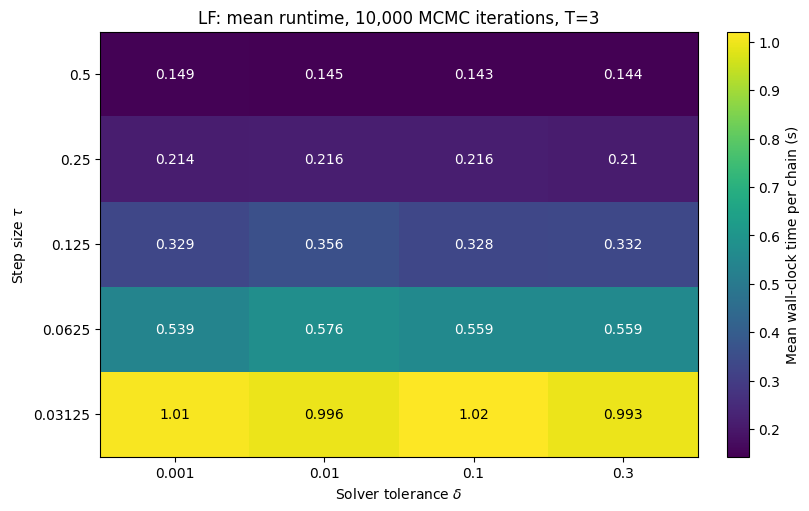

In [47]:
fig, ax, mean_seconds, counts, taus_plot, tols_plot = plot_compute_heatmap(
    base=base,
    method='LF',
    T=float(T),
    length=10_000,
)

# fig.savefig("compute_time_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
deltas = jnp.array([1e-3, 1e-2, 1e-1, 3e-1])

cutoffs = jnp.log(deltas)
cutoffs

Array([-6.90775528, -4.60517019, -2.30258509, -1.2039728 ], dtype=float64)

In [ ]:
def load_result(base, method, tau, tol,T, length, run):
    """
    navigating the file path generated from the forloops. 
    result = load_result(
        base,
        method = "AA",
        tau = 2**-1,
        T = 1.0,
        length = 1000,
        run = 3,
    )

    q = result["q"]
    deltaHs = result["deltaHs"]
    accepted = result["accepted"]
    runtime = result["runtime"]

    """
    path = (
        Path(base)
        / method
        / f"tau_{float(tau):.12g}"
        / f"T_{float(T):.1f}"
        / f"tol_{float(tol):0.12g}"
        / f"len_{int(length)}"
        / f"run_{run}.npz"
    )
    return jnp.load(path)
start = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)

repo_root = next(
    p for p in (start, *start.parents)
    if (p / "CHMC").is_dir()
)

base = repo_root / "CHMC/scripts/compute_heatmaps/neals_results"

result = load_result(
    base, methods[0], taus[0], tols[0], T, 10_000, 0
)

NameError: name 'deltaHs' is not defined

In [44]:
result_LF = load_result(
    base, 'LF', taus[0], tols[0], T, 10_000, 0
)
result_AA = load_result(
    base, 'AA_m=3', taus[0], tols[0], T, 10_000, 0
)

In [46]:
print(jnp.sum(result_LF['accepted']))
print(jnp.sum(result_AA['accepted']))

3
0


In [63]:
type(result_LF['deltaHs'])

numpy.ndarray

In [60]:
print(f'{val}' for val in cutoffs)

<generator object <genexpr> at 0x12e95be80>


In [65]:
count = [jnp.sum(result_LF["deltaHs"] <= val) for val in cutoffs]
print(count)

[Array(9995, dtype=int64), Array(9995, dtype=int64), Array(9996, dtype=int64), Array(9997, dtype=int64)]


In [ ]:
CHMC/scripts/compute_heatmaps/neals_results/AA_m=3/tau_0.5/T_3.0/tol_0.001/len_10000/run_0.npz
CHMC/scripts/compute_heatmaps/neals_results/AA_m=3/tau_0.5/T_3.0/tol_0.001/len_10000/run_0.npz

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (3946750966.py, line 1)

In [ ]:
'CHMC/scripts/compute_heatmaps/neals_results/AA_m=3/tau_0.5/T_3.0/tol_0.001/len_10000/run_0.npz'